# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# creditLimit is stored as TEXT, so it must be CAST to a number before comparing.
# In SQLite a TEXT value always counts as "greater than" a number, so without the CAST
# all 11 California customers pass the filter, including Boards & Toys Co. at only 11,000.
df_california = pd.read_sql("""
SELECT customerNumber,
       customerName,
       city,
       state,
       CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY creditLimit DESC;
""", conn)
df_california

,customerNumber,customerName,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,San Jose,CA,77600.0
6,129,Mini Wheels Co.,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Burbank,CA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
df_collect = pd.read_sql("""
SELECT customerNumber,
       customerName,
       city,
       country
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
""", conn)
df_collect

,customerNumber,customerName,city,country
0,471,"Australian Collectables, Ltd",Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Melbourne,Australia
2,382,Salzburg Collectables,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Tsawassen,Canada
4,227,Heintze Collectables,Århus,Denmark
5,353,Reims Collectables,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Munich,Germany
7,409,Stuttgart Collectable Exchange,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dublin,Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

### Answer

My WHERE clause has two conditions joined by **AND**, so a customer is only kept if it passes **both** checks:

1. `country <> 'USA'` means "country is not equal to USA". It removes every US-based customer, which leaves only international customers.
2. `customerName LIKE '%Collect%'` looks for the letters "Collect" anywhere in the customer's name. The `%` signs are wildcards meaning "anything can come before or after", so it catches names such as *Australian **Collect**ors, Co.*, *UK **Collect**ables, Ltd.* and *Clover **Collect**ions, Co.*

Because the conditions are joined by AND rather than OR, a US store with "Collect" in its name (such as *Cambridge Collectables Co.*) is excluded, and an international store without "Collect" in its name is also excluded. The result is only the 15 international customers whose names fit the "collect them all" theme.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
df_state_credit = pd.read_sql("""
SELECT state,
       COUNT(customerNumber) AS num_customers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
""", conn)
df_state_credit

,state,num_customers,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

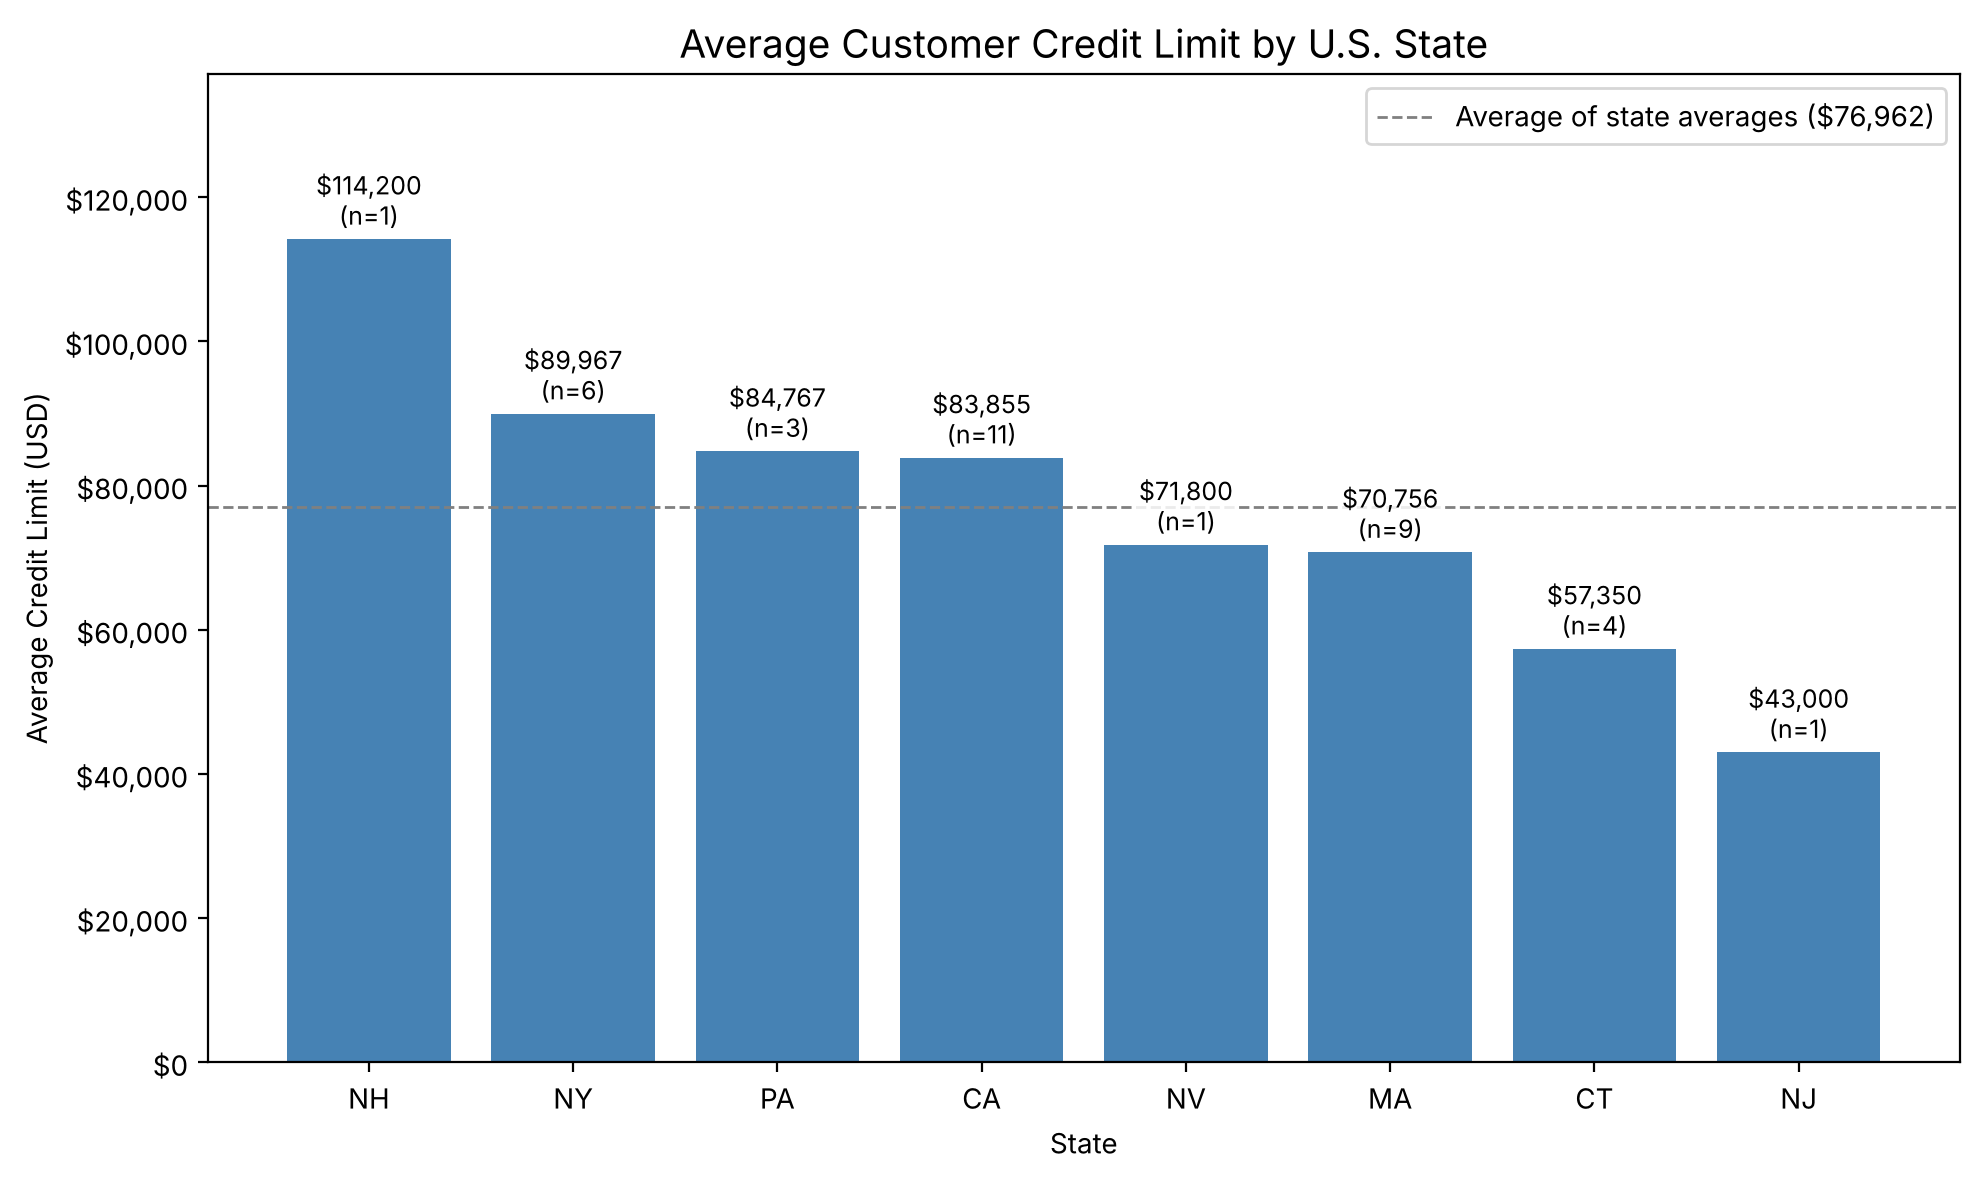

In [5]:
# Bar chart: one bar per state, sorted so the comparison is easy to read
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(df_state_credit['state'], df_state_credit['avg_credit_limit'], color='steelblue')

# Label each bar with its average and number of customers
for bar, avg, n in zip(bars, df_state_credit['avg_credit_limit'], df_state_credit['num_customers']):
    ax.annotate(f"${avg:,.0f}\n(n={n})", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))

overall = df_state_credit['avg_credit_limit'].mean()
ax.axhline(overall, color='gray', linestyle='--', linewidth=1, label=f'Average of state averages (${overall:,.0f})')

ax.set_title('Average Customer Credit Limit by U.S. State', fontsize=14)
ax.set_xlabel('State')
ax.set_ylabel('Average Credit Limit (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_ylim(0, df_state_credit['avg_credit_limit'].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
df_top_customers = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers AS c
JOIN payments AS p
  ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
""", conn)
df_top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

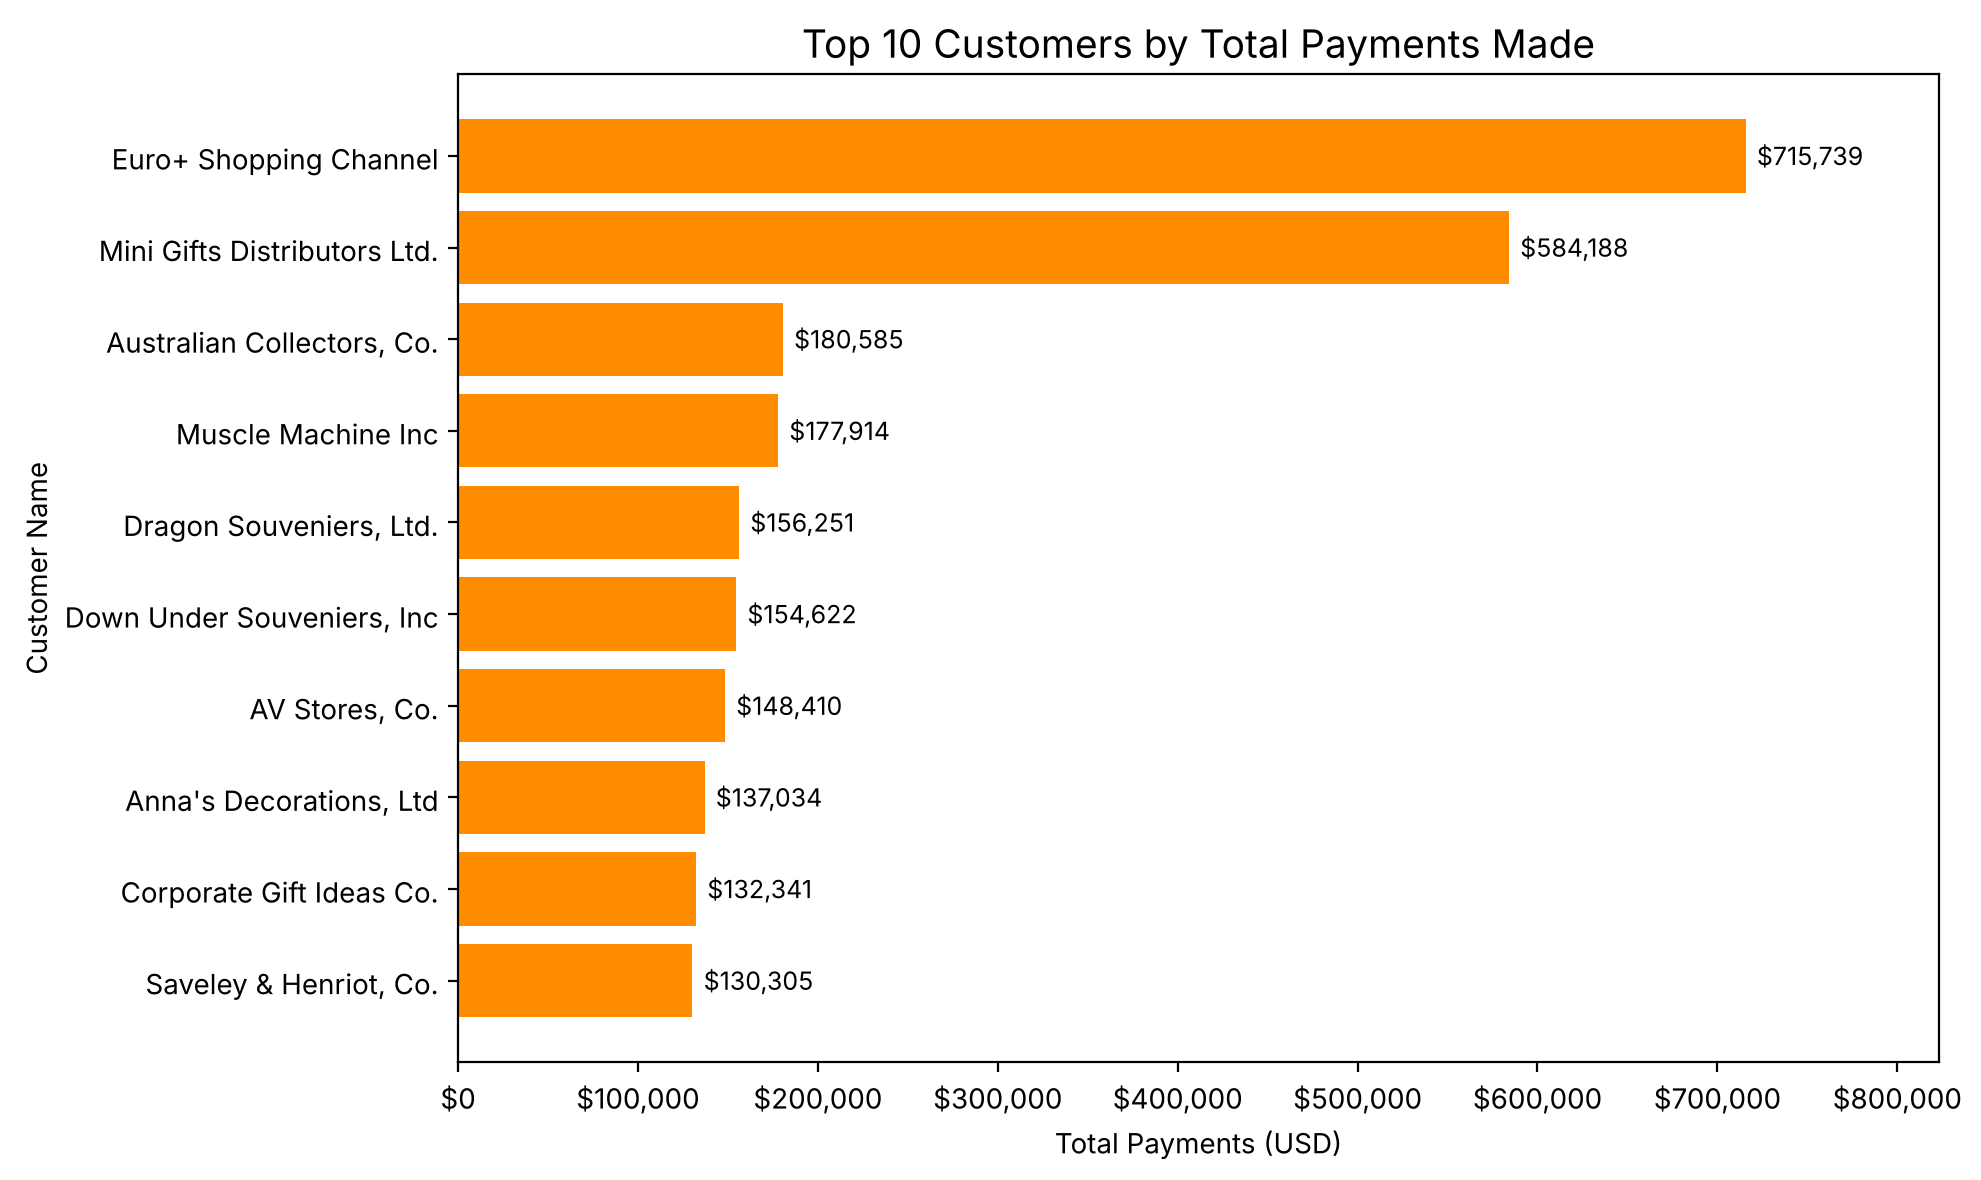

In [7]:
# Horizontal bar chart: long customer names stay readable, and the #1 customer sits at the top
plot_df = df_top_customers.sort_values('total_payments')
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_df['customerName'], plot_df['total_payments'], color='darkorange')

for bar, val in zip(bars, plot_df['total_payments']):
    ax.annotate(f"${val:,.0f}", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)

ax.set_title('Top 10 Customers by Total Payments Made', fontsize=14)
ax.set_xlabel('Total Payments (USD)')
ax.set_ylabel('Customer Name')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_xlim(0, plot_df['total_payments'].max() * 1.15)
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
df_customer_products = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       p.productCode,
       p.productName,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity
FROM customers AS c
JOIN orders AS o
  ON c.customerNumber = o.customerNumber
JOIN orderdetails AS od
  ON o.orderNumber = od.orderNumber
JOIN products AS p
  ON od.productCode = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
ORDER BY total_quantity ASC;
""", conn)
df_customer_products

,customerNumber,customerName,productCode,productName,total_quantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# COUNT(DISTINCT ...) is needed: after joining to orderdetails, each product
# appears once per order line, so a plain COUNT would count the same product many times
# (e.g. Classic Cars would show 1,010 "products" instead of 38).
# LEFT JOIN keeps products that have never been ordered (the 1985 Toyota Supra),
# so num_products reflects the full catalog for each line.
df_product_lines = pd.read_sql("""
SELECT p.productLine,
       COUNT(DISTINCT p.productCode) AS num_products,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_ordered
FROM products AS p
LEFT JOIN orderdetails AS od
  ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
""", conn)
df_product_lines

,productLine,num_products,total_quantity_ordered
0,Classic Cars,38,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

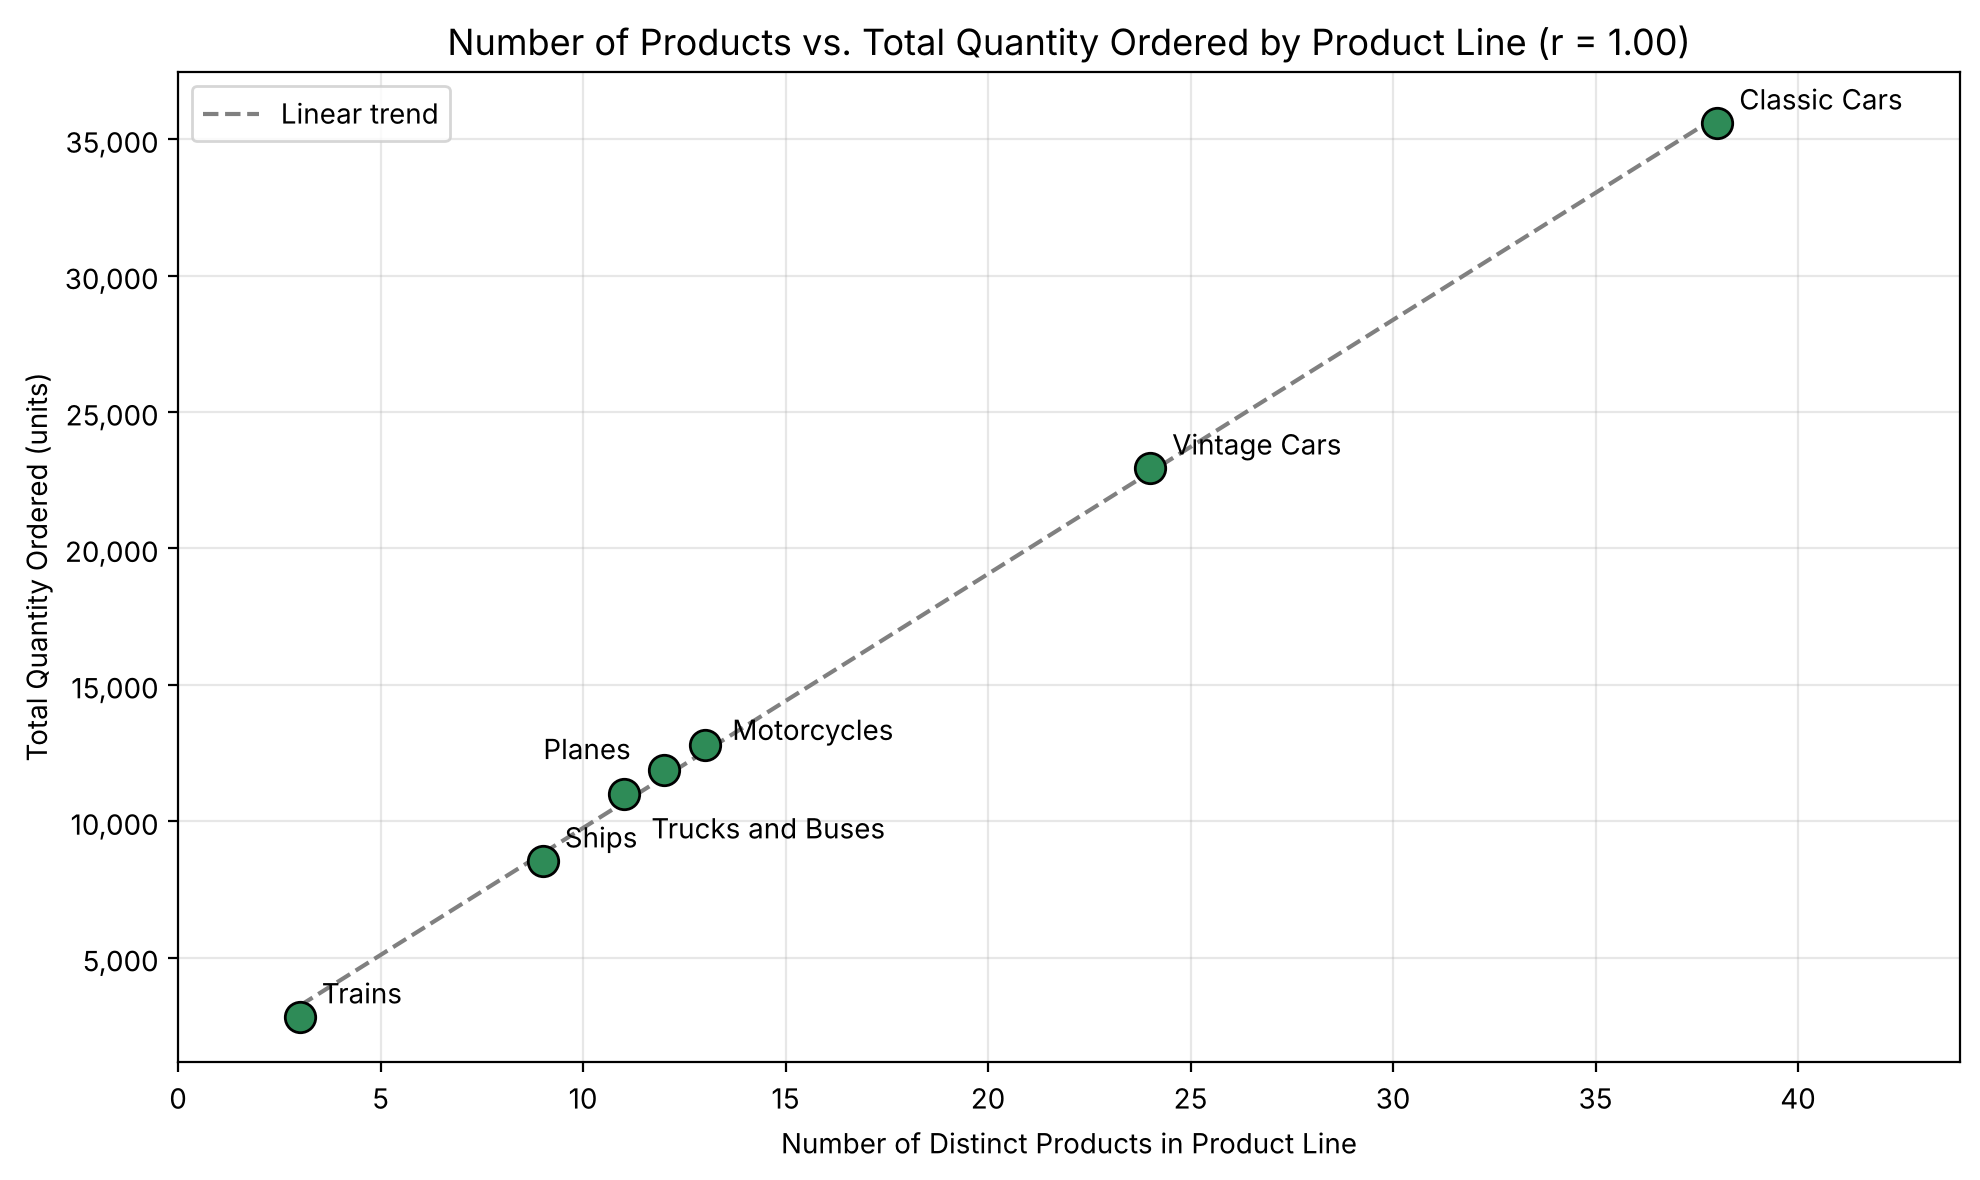

In [10]:
# Scatter plot: each point is a product line, so we can see whether
# lines with more products (x-axis) also sell more units (y-axis)
import numpy as np

x = df_product_lines['num_products']
y = df_product_lines['total_quantity_ordered']

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, s=120, color='seagreen', edgecolor='black', zorder=3)

# Custom label offsets so the tightly clustered lines (Planes, Motorcycles, Trucks) don't overlap
offsets = {'Motorcycles': (10, 2, 'left'), 'Planes': (-12, 4, 'right'), 'Trucks and Buses': (10, -16, 'left')}
for _, row in df_product_lines.iterrows():
    dx, dy, ha = offsets.get(row['productLine'], (8, 5, 'left'))
    ax.annotate(row['productLine'], (row['num_products'], row['total_quantity_ordered']),
                xytext=(dx, dy), textcoords='offset points', fontsize=10, ha=ha)

# Simple trend line to show the overall direction of the relationship
m, b = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, m * xs + b, color='gray', linestyle='--', label='Linear trend')
r = np.corrcoef(x, y)[0, 1]

ax.set_title(f'Number of Products vs. Total Quantity Ordered by Product Line (r = {r:.2f})', fontsize=13)
ax.set_xlabel('Number of Distinct Products in Product Line')
ax.set_xlim(0, x.max() + 6)
ax.set_ylabel('Total Quantity Ordered (units)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

### Answer

I used a **scatter plot**, with one dot per product line. The number of different products in the line runs along the bottom (x-axis), and the total units ordered runs up the side (y-axis). Each dot is labeled with the product line's name.

**Why this chart type:** the question is about the *relationship* between two numbers, "do lines with more products also get more orders?" A scatter plot is built for exactly that. If the dots climb from bottom-left to top-right, the two numbers rise together. If the dots are scattered with no pattern, they are unrelated. A bar chart could show either number on its own, but it makes it hard to compare both at once. The dashed trend line and the correlation value (r) in the title summarize the overall direction.

**What it shows:** the dots fall almost perfectly on a straight upward line (r ≈ 1.00). Classic Cars has the most products (38) and by far the most units ordered (35,582). Vintage Cars is second on both counts, and Trains has the fewest products (3) and the fewest units (2,818). In this data, product lines with more products did sell more units in total, and the average units sold per product is similar across lines (roughly 940–1,000).

**Caveat:** this shows that the two move together, not that adding products *causes* more orders. With only 7 product lines, it is a preliminary signal. A natural follow-up would be to compare units ordered **per product** and revenue by line before deciding to expand a range or phase one out.


### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
df_remote = pd.read_sql("""
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.officeCode,
       o.city AS officeCity,
       o.country AS officeCountry,
       e.reportsTo AS supervisorNumber,
       s.firstName || ' ' || s.lastName AS supervisorName,
       s.jobTitle AS supervisorJobTitle
FROM employees AS e
JOIN offices AS o
  ON e.officeCode = o.officeCode
LEFT JOIN employees AS s
  ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(employeeNumber) < 5
)
ORDER BY e.officeCode, e.employeeNumber;
""", conn)
df_remote

,employeeNumber,firstName,lastName,jobTitle,officeCode,officeCity,officeCountry,supervisorNumber,supervisorName,supervisorJobTitle
0,1188,Julie,Firrelli,Sales Rep,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
4,1621,Mami,Nishi,Sales Rep,5,Tokyo,Japan,1056,Mary Patterson,VP Sales
5,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,Japan,1621,Mami Nishi,Sales Rep
6,1088,William,Patterson,Sales Manager (APAC),6,Sydney,Australia,1056,Mary Patterson,VP Sales
7,1611,Andy,Fixter,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
9,1619,Tom,King,Sales Rep,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

### Answer

I split the problem into two questions: **which offices are small**, and **who works in them**.

- **Subquery (which offices):** `SELECT officeCode FROM employees GROUP BY officeCode HAVING COUNT(employeeNumber) < 5`. Grouping the employees table by office and counting rows gives the headcount per office. Because the filter is on an aggregate (the count), it has to go in `HAVING`, not `WHERE`. This returns the office codes 2, 3, 5, 6 and 7. Office 1 (6 people) and office 4 (5 people) are left out because "fewer than 5" means 4 or fewer.
- **Main query (who works there):** `WHERE e.officeCode IN (subquery)` keeps only employees whose office code is in that list. Using a subquery instead of typing `IN ('2','3','5','6','7')` means the query stays correct if staff move or offices are added.

To give management what they need for the transition, I also joined `offices` for the office city and country. I then self-joined `employees` to itself on `e.reportsTo = s.employeeNumber` to get each employee's supervisor name and title. I used a **LEFT JOIN** for the supervisor so that anyone without a supervisor (such as the President) would still appear instead of being silently dropped.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [14]:
# Begin your code here
# 1. How big is each table? (gives a sense of scope before filtering)
tables = ['movie_basics', 'movie_ratings', 'directors', 'writers', 'principals', 'persons', 'known_for', 'movie_akas']
row_counts = pd.DataFrame({
    'table': tables,
    'rows': [pd.read_sql(f'SELECT COUNT(*) AS n FROM {t};', conn4)['n'][0] for t in tables]
})
row_counts

,table,rows
0,movie_basics,146144
1,movie_ratings,73856
2,directors,291174
3,writers,255873
4,principals,1028186
5,persons,606648
6,known_for,1638260
7,movie_akas,331703


In [15]:
# 2. Movies by release year: confirms the 2010-2019 range and shows the bad future-dated rows we must exclude
df_years = pd.read_sql("""
SELECT start_year,
       COUNT(*) AS num_movies
FROM movie_basics
GROUP BY start_year
ORDER BY start_year;
""", conn4)
df_years

,start_year,num_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [16]:
# 3. Null check on the fields I plan to use (2010-2019 only)
df_nulls = pd.read_sql("""
SELECT COUNT(*)                                     AS total_movies,
       SUM(runtime_minutes IS NULL)                 AS null_runtime,
       SUM(genres IS NULL)                          AS null_genres,
       SUM(original_title IS NULL)                  AS null_original_title,
       SUM(movie_id NOT IN (SELECT movie_id FROM movie_ratings)) AS no_rating
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
""", conn4)
df_nulls

,total_movies,null_runtime,null_genres,null_original_title,no_rating
0,145081,30765,5359,20,71225


In [17]:
# 4. How many votes do rated movies get? Most have very few, so their ratings are unreliable
df_votes = pd.read_sql("""
SELECT CASE
         WHEN numvotes < 100   THEN '1. under 100'
         WHEN numvotes < 1000  THEN '2. 100 - 999'
         WHEN numvotes < 10000 THEN '3. 1,000 - 9,999'
         ELSE                       '4. 10,000+'
       END AS vote_bucket,
       COUNT(*) AS num_movies,
       ROUND(AVG(averagerating), 2) AS avg_rating
FROM movie_ratings AS r
JOIN movie_basics AS b ON r.movie_id = b.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
GROUP BY vote_bucket
ORDER BY vote_bucket;
""", conn4)
df_votes

,vote_bucket,num_movies,avg_rating
0,1. under 100,45103,6.60
1,2. 100 - 999,19136,5.74
2,"3. 1,000 - 9,999",6939,6.14
3,"4. 10,000+",2678,6.54


In [18]:
# 5. Pull rated movies with genres, keeping only those with 1,000+ votes so each rating
#    reflects a real audience. Nulls are excluded (not filled), per the instructions.
df_movies = pd.read_sql("""
SELECT b.movie_id,
       b.primary_title,
       b.start_year,
       b.runtime_minutes,
       b.genres,
       r.averagerating,
       r.numvotes
FROM movie_basics AS b
JOIN movie_ratings AS r
  ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.genres IS NOT NULL
  AND r.numvotes >= 1000;
""", conn4)
print(f"{len(df_movies):,} movies with 1,000+ votes")
df_movies.head()

9,615 movies with 1,000+ votes


,movie_id,primary_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0069049,The Other Side of the Wind,2018,122.0,Drama,6.9,4517
1,tt0249516,Foodfight!,2012,91.0,"Action,Animation,Comedy",1.9,8248
2,tt0293069,Dark Blood,2012,86.0,Thriller,6.6,1053
3,tt0315642,Wazir,2016,103.0,"Action,Crime,Drama",7.1,15378
4,tt0323808,The Wicker Tree,2011,96.0,"Drama,Horror",3.9,2328


In [19]:
# 6. genres holds up to 3 comma-separated values (e.g. "Action,Crime,Drama").
#    Split them so each movie counts once toward EACH of its genres.
df_genre = df_movies.assign(genre=df_movies['genres'].str.split(',')).explode('genre')

genre_stats = (df_genre.groupby('genre')
               .agg(num_movies=('movie_id', 'count'),
                    avg_rating=('averagerating', 'mean'),
                    median_votes=('numvotes', 'median'))
               .query('num_movies >= 40')        # drop genres too small to compare (e.g. Game-Show, News)
               .sort_values('avg_rating', ascending=False)
               .round(2))

overall_rating = df_movies['averagerating'].mean()
overall_votes = df_movies['numvotes'].median()
print(f"Benchmark across all {len(df_movies):,} movies: average rating {overall_rating:.2f}, median votes {overall_votes:,.0f}")
genre_stats

Benchmark across all 9,615 movies: average rating 6.25, median votes 3,467


,num_movies,avg_rating,median_votes
genre,,,
Documentary,741,7.27,2259.0
Biography,701,6.96,4559.0
Sport,196,6.93,2753.5
History,387,6.89,3590.0
Music,283,6.75,3637.0
War,163,6.72,3907.0
Animation,376,6.68,5289.5
Musical,70,6.54,2372.5
Drama,5047,6.49,3789.0


In [20]:
# 7. Does runtime relate to rating and audience size? (runtimes over 300 min treated as data errors)
df_runtime = pd.read_sql("""
SELECT CASE
         WHEN b.runtime_minutes < 90   THEN '1. under 90 min'
         WHEN b.runtime_minutes <= 120 THEN '2. 90 - 120 min'
         ELSE                               '3. over 120 min'
       END AS runtime_bucket,
       COUNT(*) AS num_movies,
       ROUND(AVG(r.averagerating), 2) AS avg_rating,
       ROUND(AVG(r.numvotes)) AS avg_votes
FROM movie_basics AS b
JOIN movie_ratings AS r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes IS NOT NULL
  AND b.runtime_minutes <= 300
  AND r.numvotes >= 1000
GROUP BY runtime_bucket
ORDER BY runtime_bucket;
""", conn4)
df_runtime

,runtime_bucket,num_movies,avg_rating,avg_votes
0,1. under 90 min,1779,5.74,8304.0
1,2. 90 - 120 min,5979,6.22,24363.0
2,3. over 120 min,1848,6.83,49764.0


## Initial Exploration Findings

- **Scope:** `movie_basics` holds 146,144 titles, but only about half (73,856) have a rating. A small number of rows have release years after 2019, up to an impossible 2115, so I limited everything to 2010–2019.
- **Missing data:** among 2010–2019 titles, about 30,800 have no runtime and about 5,400 have no genre. I excluded these rows rather than filling them in.
- **Most ratings rest on very few votes:** about 61% of rated films have fewer than 100 votes. I kept only films with **1,000+ votes** (9,615 films), so that each rating reflects a real audience.
- **The genres that rate best are not the genres the most people watch:**
  - **Documentary, Biography, History and Sport** have the highest average ratings (6.9–7.3), but they draw fewer votes.
  - **Adventure, Fantasy, Sci-Fi and Action** draw the most votes (5,000–8,600 median), but they rate *below* the overall average of 6.25.
  - **Horror** has the lowest average rating (5.28) of any major genre.
- **A few genres do both:** **Animation and Biography** stand clearly above the overall average for *both* rating and audience size. History, Music, War, Drama, Romance and Family are also above both lines, though closer to them, and Crime only just clears the rating line (6.27 vs. 6.25).
- **Longer films rate higher and draw bigger audiences:** films over 120 minutes average 6.83 vs. 5.74 for films under 90 minutes, with about 6× the votes.
- **2019 looks incomplete:** 2019 has far fewer rated films than 2017, and an unusually high average rating, so year-over-year trends should be treated with caution.

## Business Question

> **A studio has a fixed production budget for 2–3 new films. Which genres deliver *both* above-average audience ratings *and* above-average audience reach? And should the studio prioritize those "sweet-spot" genres (such as Animation and Biography) over high-volume but lower-rated genres such as Action, Sci-Fi and Horror?**

**Why it matters:** ratings drive word of mouth and long-term catalog value, and vote counts are a stand-in for how many people actually watched. A genre that does well on only one of the two is a riskier bet.

**How to answer it further:** add box-office or budget data to measure return on investment. Look at each genre's ratings over time, and check whether particular directors or writers explain the high ratings in the sweet-spot genres.

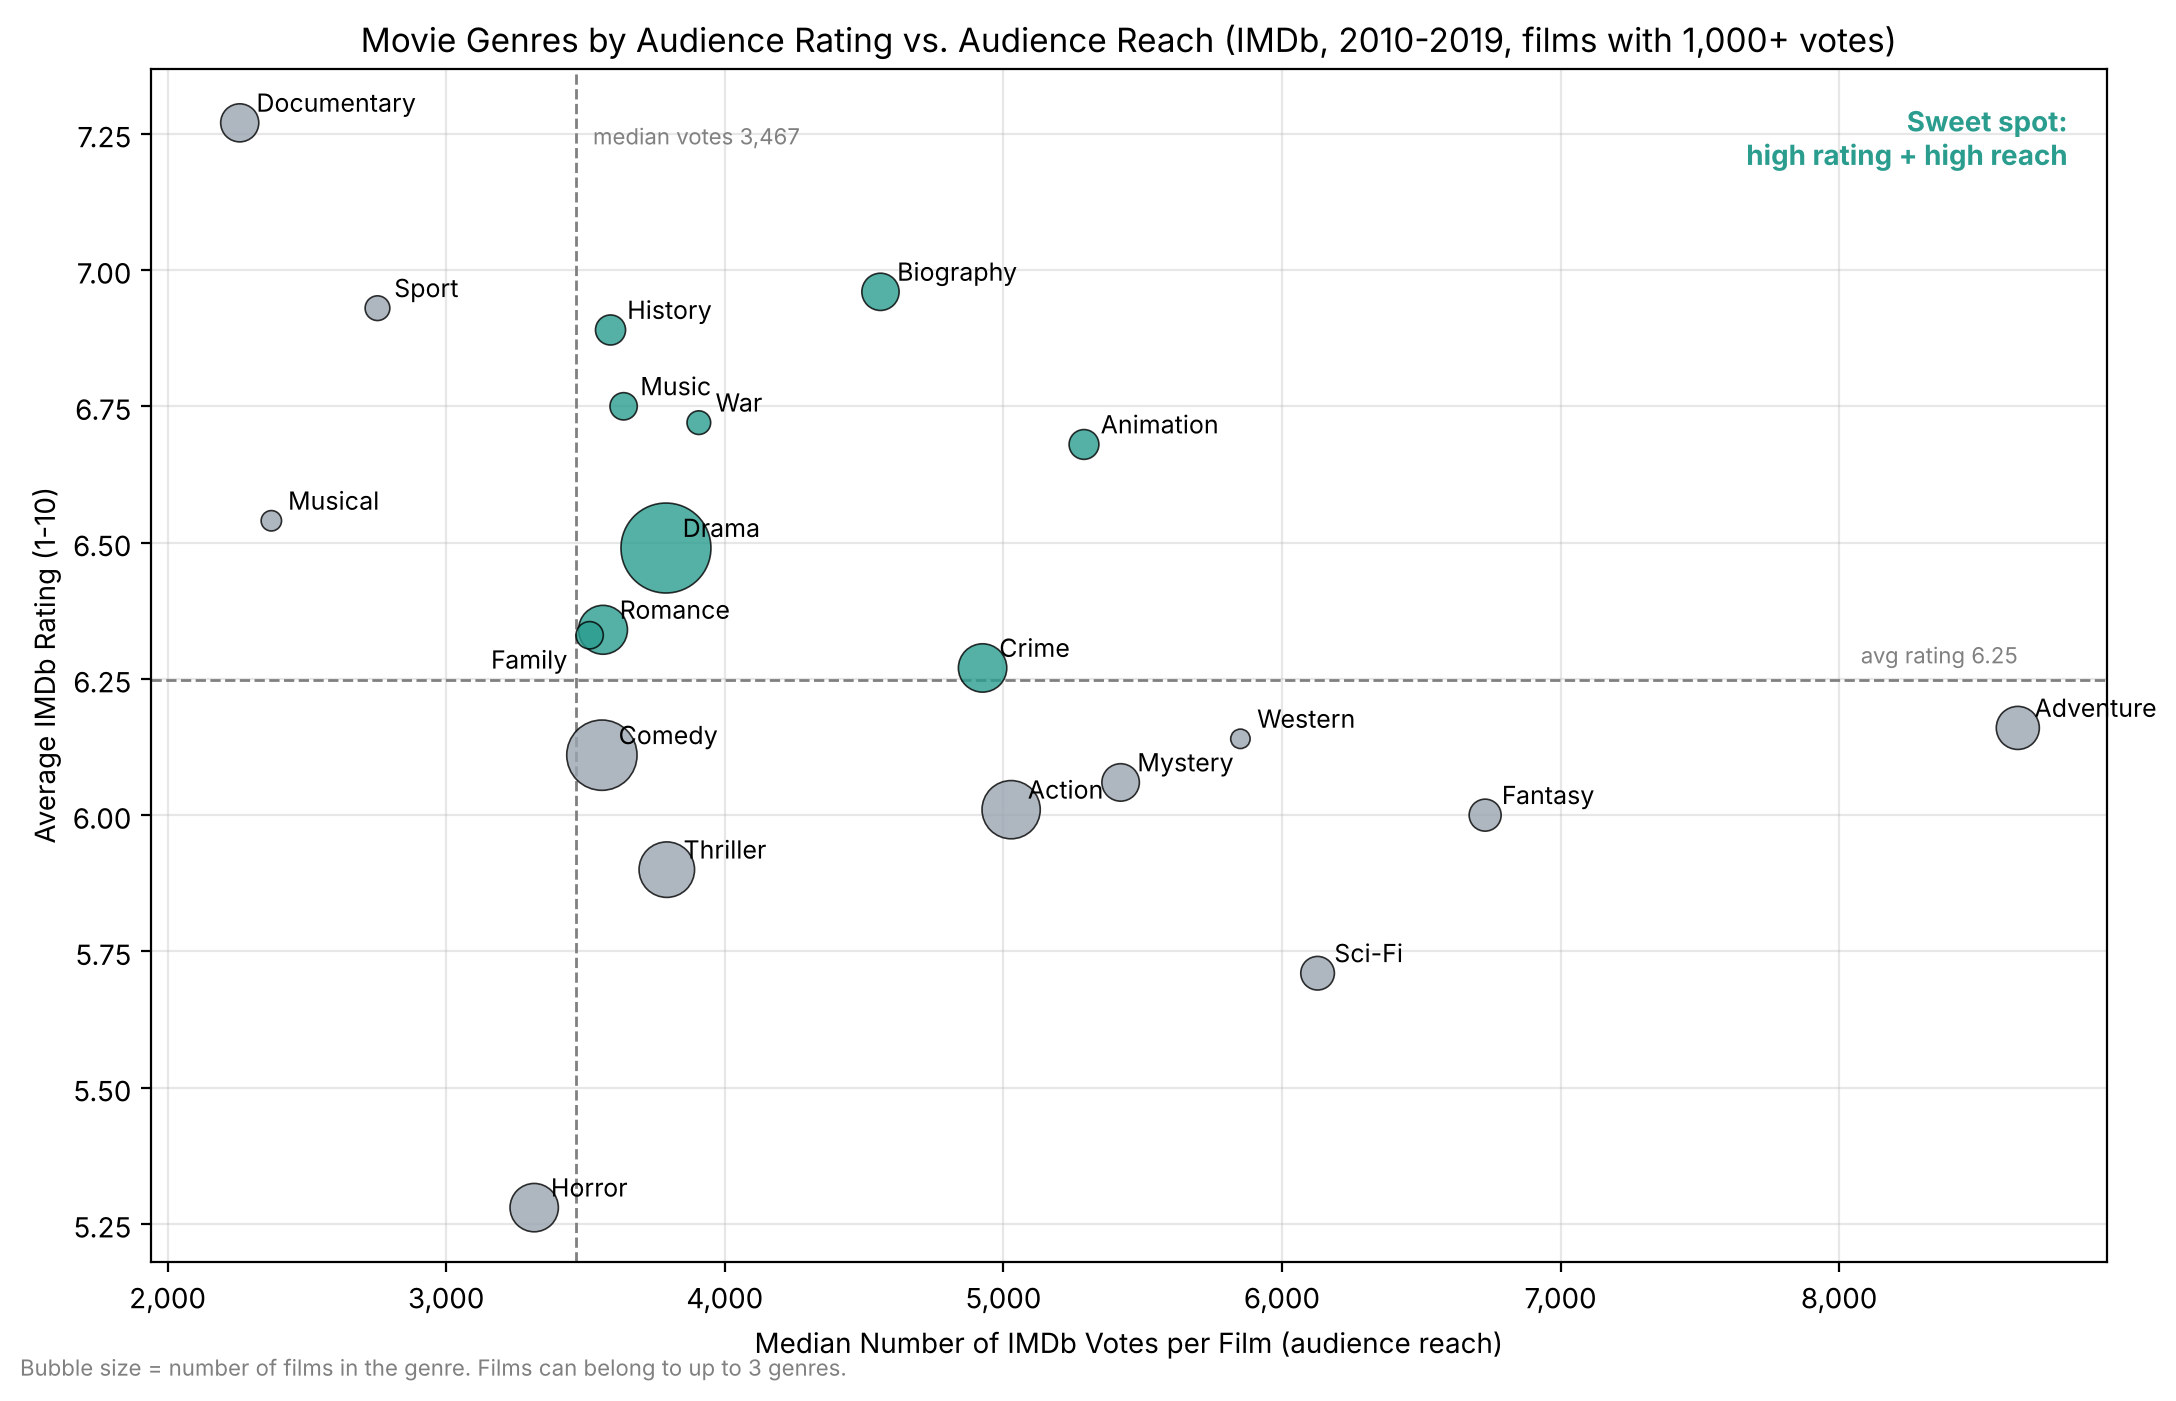

In [21]:
# 8. Visual for the business question: rating (quality) vs. median votes (reach) for each genre
import numpy as np
gs = genre_stats.reset_index()
sweet = (gs['avg_rating'] > overall_rating) & (gs['median_votes'] > overall_votes)
colors = np.where(sweet, '#2a9d8f', '#9aa5b1')

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(gs['median_votes'], gs['avg_rating'], s=gs['num_movies'] / 5 + 40,
           c=colors, alpha=0.8, edgecolor='black', linewidth=0.6, zorder=3)

for _, row in gs.iterrows():
    # Family and Romance sit almost on top of each other, so push Family's label to the left
    offset, ha = ((-8, -12), 'right') if row['genre'] == 'Family' else ((6, 4), 'left')
    ax.annotate(row['genre'], (row['median_votes'], row['avg_rating']),
                xytext=offset, textcoords='offset points', fontsize=9, ha=ha)

ax.axhline(overall_rating, color='gray', linestyle='--', linewidth=1)
ax.axvline(overall_votes, color='gray', linestyle='--', linewidth=1)
ax.text(gs['median_votes'].max(), overall_rating + 0.03, f'avg rating {overall_rating:.2f}', ha='right', fontsize=8, color='gray')
ax.text(overall_votes + 60, gs['avg_rating'].max(), f'median votes {overall_votes:,.0f}', fontsize=8, color='gray', va='top')
ax.text(0.98, 0.97, 'Sweet spot:\nhigh rating + high reach', transform=ax.transAxes,
        ha='right', va='top', fontsize=10, color='#2a9d8f', fontweight='bold')

ax.set_title('Movie Genres by Audience Rating vs. Audience Reach (IMDb, 2010-2019, films with 1,000+ votes)', fontsize=12)
ax.set_xlabel('Median Number of IMDb Votes per Film (audience reach)')
ax.set_ylabel('Average IMDb Rating (1-10)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(alpha=0.3)
fig.text(0.01, 0.01, 'Bubble size = number of films in the genre. Films can belong to up to 3 genres.', fontsize=8, color='gray')
plt.tight_layout()
plt.savefig('images/genre_rating_vs_reach.png', dpi=200, bbox_inches='tight')
plt.show()

**What the chart shows:** most genres fall into one of two groups. The well-reviewed genres at the top-left (Documentary, Sport) have smaller audiences, and the crowd-pleasers at the bottom-right (Adventure, Fantasy, Sci-Fi, Action) have below-average ratings. **Animation** stands out in the green top-right sweet spot, with high reach (5,290 median votes) and strong ratings (6.68). **Biography** follows closely with 4,559 median votes and a 6.96 rating. **Horror** sits at the bottom, with the lowest ratings and below-median reach. As a preliminary recommendation, the studio should look first at Animation and Biography projects. This is a first look based on ratings and votes only, not revenue.

## Potential Data Cleaning Tasks

1. **Remove out-of-range years:** drop movies with `start_year` after 2019 (1,063 rows, including an impossible 2115).
2. **Null handling:** exclude rows with null `runtime_minutes` (about 30,800) or `genres` (about 5,400) from any analysis that uses them. Many tables also have heavily null columns: `principals.job` is about 83% null and `persons.birth_year` is mostly null.
3. **Unrated movies:** about half of `movie_basics` has no match in `movie_ratings`. Use an inner join, and state that the results only describe rated films.
4. **Low-vote ratings:** about 61% of rated films have fewer than 100 votes. Set a minimum vote threshold (I used 1,000) or use a weighted rating.
5. **Split multi-value genres:** `genres` stores up to 3 values in one comma-separated string. Normalize it into a separate movie–genre table (one row per movie per genre).
6. **Runtime outliers:** some runtimes are unrealistic (the maximum is 51,420 minutes, and 123 films are over 300 minutes). Cap these or investigate them.
7. **Duplicate rows:** `directors` has 291,174 rows but only 163,535 unique movie–director pairs, and `writers` has 255,873 rows but only 178,352 unique pairs. De-duplicate both before counting people.
8. **Duplicate or ambiguous titles:** 1,859 title + year combinations appear more than once, so always join on `movie_id`, not on the title.
9. **Inconsistent text formats:** `principals.characters` stores JSON-style lists (`["Role"]`), and `persons.primary_profession` is comma-separated. Parse and standardize both.
10. **Standardize titles:** `primary_title` differs from `original_title` for about 14,500 films, and some `original_title` values are null. Pick one consistent display title.

In [22]:
# Close the connection
conn4.close()